# 06 · Robustness test sets
**Owner:** Chaitanya Sai Meka

Phase 2. The Corr2Cause authors made two harder copies of the test set:
* **paraphrasing**: every hypothesis is reworded, e.g. "A directly causes B" becomes "A directly affects B"
* **refactorization**: the variables are renamed, e.g. A, B, C become Z, Y, X

We clean them the same way as notebook 01, rename the variables back to A–F (our entity schema), check for
leakage and explore them. Notebooks 07–10 test every method on all three test sets.

In [1]:
# ─── IMPORTS ─────
import sys
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

sys.path.insert(0, "../src")
from c2c.reader import rename_variables, TEMPLATE_TO_RELATION
from c2c.parsing import parse_hypothesis

In [2]:
# ─── LOAD DATA ─────
hf_hub_download("causal-nlp/corr2cause", "perturbation_by_paraphrasing_test.csv", repo_type="dataset", local_dir="../data/raw")
hf_hub_download("causal-nlp/corr2cause", "perturbation_by_refactorization_test.csv", repo_type="dataset", local_dir="../data/raw")

paraphrasing = pd.read_csv("../data/raw/perturbation_by_paraphrasing_test.csv")
refactorization = pd.read_csv("../data/raw/perturbation_by_refactorization_test.csv")
test = pd.read_csv("../data/processed/test.csv")   # the original test set from notebook 01

In [3]:
paraphrasing.head()

,Unnamed: 0,premise,hypothesis,relation,id,input,label
0,0,Suppose there is a closed system of 2 variable...,A directly affects B.,neutral,num_nodes=2__mec_id=1__node_i=1__node_j=2__cau...,Premise: Suppose there is a closed system of 2...,0
1,1,Suppose there is a closed system of 2 variable...,A influences B through some mediator(s).,contradiction,num_nodes=2__mec_id=1__node_i=1__node_j=2__cau...,Premise: Suppose there is a closed system of 2...,2
2,2,Suppose there is a closed system of 2 variable...,B directly affects A.,neutral,num_nodes=2__mec_id=1__node_i=1__node_j=2__cau...,Premise: Suppose there is a closed system of 2...,0
3,3,Suppose there is a closed system of 2 variable...,B influences A through some mediator(s).,contradiction,num_nodes=2__mec_id=1__node_i=1__node_j=2__cau...,Premise: Suppose there is a closed system of 2...,2
4,4,Suppose there is a closed system of 2 variable...,A and B together cause some other variable(s).,contradiction,num_nodes=2__mec_id=1__node_i=1__node_j=2__cau...,Premise: Suppose there is a closed system of 2...,2


In [4]:
refactorization.head()

,Unnamed: 0,label,input
0,0,0,Premise: Suppose there is a closed system of 2...
1,1,0,Premise: Suppose there is a closed system of 2...
2,2,0,Premise: Suppose there is a closed system of 2...
3,3,0,Premise: Suppose there is a closed system of 2...
4,4,0,Premise: Suppose there is a closed system of 2...


In [5]:
print(paraphrasing.shape, refactorization.shape, test.shape)

(2246, 7) (2246, 3) (1162, 7)


In [6]:
# ─── STEP 1: MISSING VALUES AND DUPLICATES ─────
paraphrasing.isnull().sum()

Unnamed: 0    0
premise       0
hypothesis    0
relation      0
id            0
input         0
label         0
dtype: int64

In [7]:
refactorization.isnull().sum()

Unnamed: 0    0
label         0
input         0
dtype: int64

In [8]:
# the same input can appear twice: "A directly affects B" is both a "parent" claim for (A, B) and a "child" claim for (B, A)
print(paraphrasing["input"].duplicated().sum(), refactorization["input"].duplicated().sum())

724 362


In [9]:
# a repeated input should always have the same label
print(paraphrasing.groupby("input")["label"].nunique().max(), refactorization.groupby("input")["label"].nunique().max())

1 1


No missing values. Repeated inputs always have the same label. The original test set keeps both the "parent" and the
"child" row too, so we keep them here as well.

In [10]:
# ─── STEP 2: SPLIT INPUT INTO PREMISE AND HYPOTHESIS ─────
# the same steps as notebook 01
paraphrasing["input"] = paraphrasing["input"].str.replace(r"\s+", " ", regex=True).str.strip()
paraphrasing["premise"] = paraphrasing["input"].str.split("Hypothesis:").str[0].str.replace("Premise:", "").str.strip()
paraphrasing["hypothesis"] = paraphrasing["input"].str.split("Hypothesis:").str[1].str.strip()

refactorization["input"] = refactorization["input"].str.replace(r"\s+", " ", regex=True).str.strip()
refactorization["premise"] = refactorization["input"].str.split("Hypothesis:").str[0].str.replace("Premise:", "").str.strip()
refactorization["hypothesis"] = refactorization["input"].str.split("Hypothesis:").str[1].str.strip()

refactorization[["premise", "hypothesis", "label"]].head()

,premise,hypothesis,label
0,Suppose there is a closed system of 2 variable...,Z directly causes Y.,0
1,Suppose there is a closed system of 2 variable...,Z causes something else which causes Y.,0
2,Suppose there is a closed system of 2 variable...,Y directly causes Z.,0
3,Suppose there is a closed system of 2 variable...,"Y is a cause for Z, but not a direct one.",0
4,Suppose there is a closed system of 2 variable...,"There exists at least one collider (i.e., comm...",0


In [11]:
# ─── STEP 3: LABELS ─────
# paraphrasing uses three labels (entailment / neutral / contradiction); only entailment means "valid"
pd.crosstab(paraphrasing["relation"], paraphrasing["label"])

label,0,1,2
relation,,,
contradiction,0,0,1192
entailment,0,342,0
neutral,712,0,0


In [12]:
paraphrasing["label"] = (paraphrasing["label"] == 1).astype(int)
print(paraphrasing["label"].value_counts().to_dict(), refactorization["label"].value_counts().to_dict())

{0: 1904, 1: 342} {0: 1904, 1: 342}


In [13]:
# ─── STEP 4: TRUE CLAIM TYPE ─────
# we need the true claim type to check the readers in notebook 07
# original test: from the template column
test["relation_true"] = test["template"].map(TEMPLATE_TO_RELATION)

# paraphrasing: the id says the template, e.g. "...__causal_relation=parent__prob=0.50"
template = paraphrasing["id"].str.extract(r"causal_relation=(.*?)__")[0]
template = template.str.replace("non-parent_ancestor", "non-parent ancestor").str.replace("non-child_descendant", "non-child descendant")
paraphrasing["relation_true"] = template.map(TEMPLATE_TO_RELATION)

# refactorization: the wording is the original one, so the regex parser reads it exactly
refactorization["relation_true"] = parse_hypothesis(refactorization)["relation"]

print(test["relation_true"].isnull().sum(), paraphrasing["relation_true"].isnull().sum(),
      (refactorization["relation_true"] == "unknown").sum())

0 0 0


In [14]:
# number of variables, as in notebook 01
paraphrasing["num_variables"] = paraphrasing["premise"].str.extract(r"closed system of (\d+) variables")[0].astype(int)
refactorization["num_variables"] = refactorization["premise"].str.extract(r"closed system of (\d+) variables")[0].astype(int)

In [15]:
# ─── STEP 5: RENAME THE VARIABLES TO A-F ─────
# our entity schema: the 1st variable listed in the premise is A, the 2nd is B, and so on
# we keep the raw text too, because notebook 08 tests the end-to-end model on it
print(rename_variables("Suppose there is a closed system of 3 variables, Z, Y and X. All the statistical relations among these 3 variables are as follows: Z correlates with Y.",
                       "X directly causes Z."))

('Suppose there is a closed system of 3 variables, A, B and C. All the statistical relations among these 3 variables are as follows: A correlates with B.', 'C directly causes A.')


In [16]:
test["premise_raw"] = test["premise"]
test["hypothesis_raw"] = test["hypothesis"]
paraphrasing["premise_raw"] = paraphrasing["premise"]
paraphrasing["hypothesis_raw"] = paraphrasing["hypothesis"]
refactorization["premise_raw"] = refactorization["premise"]
refactorization["hypothesis_raw"] = refactorization["hypothesis"]

# rename every refactorization row, one by one
new_premises = []
new_hypotheses = []
for premise, hypothesis in zip(refactorization["premise"], refactorization["hypothesis"]):
    new_premise, new_hypothesis = rename_variables(premise, hypothesis)
    new_premises.append(new_premise)
    new_hypotheses.append(new_hypothesis)

refactorization["premise"] = new_premises
refactorization["hypothesis"] = new_hypotheses

In [17]:
# renaming should change nothing in the paraphrasing set (it already uses A-F)
changed = 0
for premise, hypothesis in zip(paraphrasing["premise"], paraphrasing["hypothesis"]):
    if rename_variables(premise, hypothesis) != (premise, hypothesis):
        changed += 1
print("paraphrasing rows changed by renaming:", changed)

paraphrasing rows changed by renaming: 0


In [18]:
refactorization[["hypothesis_raw", "hypothesis"]].drop_duplicates().sample(5, random_state=42)

,hypothesis_raw,hypothesis
313,X causes something else which causes V.,C causes something else which causes E.
32,X directly causes Y.,C directly causes B.
1360,W directly causes U.,D directly causes F.
336,W directly causes V.,D directly causes E.
316,"There exists at least one collider (i.e., comm...","There exists at least one collider (i.e., comm..."


In [19]:
# ─── STEP 6: LEAKAGE CHECK ─────
# after renaming, every premise should be one of the 21 original test premises, never a train or validation one
train = pd.read_csv("../data/processed/train.csv")
validation = pd.read_csv("../data/processed/validation.csv")

for name, df in [("paraphrasing", paraphrasing), ("refactorization", refactorization)]:
    premises = set(df["premise"])
    print(name, len(premises), "premises | in test:", len(premises & set(test["premise"])),
          "| in train:", len(premises & set(train["premise"])), "| in validation:", len(premises & set(validation["premise"])))

paraphrasing 21 premises | in test: 21 | in train: 0 | in validation: 0
refactorization 21 premises | in test: 21 | in train: 0 | in validation: 0


In [20]:
# so both sets can use the premise ids from notebook 01
premise_id = test.drop_duplicates("premise").set_index("premise")["premise_id"]
paraphrasing["premise_id"] = paraphrasing["premise"].map(premise_id)
refactorization["premise_id"] = refactorization["premise"].map(premise_id)
print(paraphrasing["premise_id"].isnull().sum(), refactorization["premise_id"].isnull().sum())

0 0


Both sets reuse the same 21 premises as our original test set and none of the train or validation premises, so
there is no leakage. Only the hypotheses (paraphrasing) or the variable names (refactorization) change.

In [21]:
# ─── STEP 7: EDA ─────
test["test_set"] = "original"
paraphrasing["test_set"] = "paraphrasing"
refactorization["test_set"] = "refactorization"

columns = ["test_set", "premise_id", "premise_raw", "hypothesis_raw", "premise", "hypothesis", "label", "relation_true", "num_variables"]
test_sets = pd.concat([test[columns], paraphrasing[columns], refactorization[columns]], ignore_index=True)
test_sets.insert(0, "row_id", test_sets.index)   # one id per row, so later notebooks can join their predictions
test_sets.groupby("test_set").size()

test_set
original           1162
paraphrasing       2246
refactorization    2246
dtype: int64

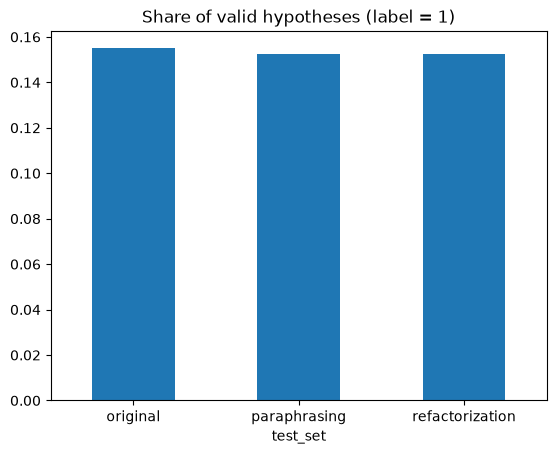

In [22]:
# label balance
test_sets.groupby("test_set")["label"].mean().plot(kind="bar", title="Share of valid hypotheses (label = 1)")
plt.xticks(rotation=0)
plt.savefig("../report/figures/robust_label_balance.png", dpi=150, bbox_inches="tight")
plt.show()

Only about 15% of the claims are valid in all three sets, so we keep using precision, recall and F1.

In [23]:
# one example of every claim type in each set (same premise, same pair of variables)
examples = test_sets[test_sets["premise_id"] == test_sets["premise_id"].min()]
examples.drop_duplicates(["test_set", "relation_true"]).pivot(index="relation_true", columns="test_set", values="hypothesis_raw")

test_set,original,paraphrasing,refactorization
relation_true,,,
collider,"There exists at least one collider (i.e., comm...",A and B together cause some other variable(s).,"There exists at least one collider (i.e., comm..."
confounder,"There exists at least one confounder (i.e., co...",Some variable(s) cause(s) both A and B.,"There exists at least one confounder (i.e., co..."
direct_cause,A directly causes B.,A directly affects B.,Z directly causes Y.
indirect_cause,A causes something else which causes B.,A influences B through some mediator(s).,Z causes something else which causes Y.


Each claim type gets **one** new wording in the paraphrasing set, e.g. a collider becomes "A and B together cause
some other variable(s)". Our Phase 1 regex parser only knows the original wordings, so it cannot read these.

In [24]:
# claim types per set
pd.crosstab(test_sets["relation_true"], test_sets["test_set"])

test_set,original,paraphrasing,refactorization
relation_true,,,
collider,193,373,373
confounder,193,373,373
direct_cause,388,750,750
indirect_cause,388,750,750


In [25]:
# number of variables per premise
premises = test_sets.drop_duplicates(["test_set", "premise_id"])
pd.crosstab(premises["test_set"], premises["num_variables"])

num_variables,2,3,4,5,6
test_set,,,,,
original,1,3,2,9,6
paraphrasing,1,3,2,9,6
refactorization,1,3,2,9,6


In [26]:
# hypotheses per premise: the new sets have about twice as many
test_sets.groupby("test_set").size() / 21

test_set
original            55.333333
paraphrasing       106.952381
refactorization    106.952381
dtype: float64

In [27]:
# ─── STEP 8: SAVE AS CSV ─────
test_sets.to_csv("../data/processed/test_sets.csv", index=False)